In [1]:
"""
Jupyter notebook for the RL coursework of the module Machine Learning for Chemical Engineers.
Academic year 2026-2027, Imperial College London.
"""
import json
from pathlib import Path

import numpy as np
from course_package import MARLEnv
from course_package.utils.helpers import (
    evaluate_expert,
    evaluate_marl_policy,
    export_submission,
    make_expert,
)
from course_package.utils.plots import plot_learning_curves, plot_reward_distribution

ROOT = Path.cwd()
DATA_DIR = ROOT / "data" / "training"
print("Working directory:", ROOT)

Working directory: /home/jovyan/work


# **Coursework 2: Reinforcement Learning**
🎯 **Objectives:**
- Solve a dynamic optimization problem using Reinforcement Learning (RL)
- Interact with a multi-agent RL environment
- Experiment with different policy training algorithms 

✏️ **Your task:** become an expert RL engineer and develop a policy-based algorithm capable of solving the proposed energy management problem.

## **1. Environment definition**
<p align="center">
  <img
    src=data/schema.png
    alt="Energy microgrid schema"
    width="500"
  />
</p>

### **Basic usage**
Create an environment instance.

In [2]:
with open(DATA_DIR / "env_config.json", "r", encoding="utf-8") as f:
    env_config = json.load(f)

env = MARLEnv(env_config)
num_agents = env.num_agents
print(f"Created MARLEnv with {num_agents} agents.")

Created MARLEnv with 5 agents.


Reset the environment (initiate a new episode).

In [3]:
obs, info = env.reset(seed=42)

Inspect the **observation space**. Observations correspond to time stamps, parameter forecasts or measurements.

In [4]:
num_features = env.observation_space.shape[1]
print("Observation space:", type(env.observation_space))
print("    - Shape:", env.observation_space.shape, "[num_agents, num_features]")
print("    - Number of features/observations:", num_features)
print("    - Feature names:", env.active_observations)

Observation space: <class 'gymnasium.spaces.box.Box'>
    - Shape: (5, 35) [num_agents, num_features]
    - Number of features/observations: 35
    - Feature names: ['hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dow_sin', 'dow_cos', 'external_temp', 'external_temp_pred1', 'external_temp_pred2', 'indoor_temp', 'indoor_temp_setpoint', 'setpoint_difference', 'hvac_mode', 'grid_cost_coeff', 'grid_cost_coeff_pred1', 'grid_cost_coeff_pred2', 'ev_soc', 'pv_generation', 'domestic_load', 'domestic_load_pred1', 'domestic_load_pred2', 'ev_availability', 'ev_trip_demand', 'ev_time_to_departure', 'ev_required_soc_departure', 'rated_power', 'cop', 'installed_capacity', 'battery_capacity', 'battery_soc_min', 'b_in_max', 'b_out_max', 'ch_efficiency', 'disch_efficiency', 'consumption']


<div class="alert alert-block alert-warning">
<b>⚠️Attention:</b> observations are already normalized to $[-1, 1]$.
</div>

Besides time-varying signals, every agent also observes static features of its own prosumer: heat pump (`rated_power`, `cop`), PV (`installed_capacity`) and EV battery (`battery_capacity`, `battery_soc_min`, `b_in_max`, `b_out_max`, `ch_efficiency`, `disch_efficiency`, `consumption`). These let a single shared policy behave differently for different prosumers.

In [5]:
num_actions = env.action_space.shape[1]
print("Action space:", type(env.action_space))
print("    - Shape:", env.action_space.shape, "[num_agents, num_actions]")
print("    - Number of actions:", num_actions)

# Sample a random action
random_action = env.action_space.sample()
print("Random action (agent 3):", random_action[3, :])

Action space: <class 'gymnasium.spaces.box.Box'>
    - Shape: (5, 2) [num_agents, num_actions]
    - Number of actions: 2
Random action (agent 3): [-0.00664932  0.6917046 ]


Take action, observe reward, and move to the next state (`step()` method). `step()` takes the **joint action** of all agents, one row per agent (`[num_agents, num_actions]`), and returns one observation row and one reward per agent.

In [6]:
next_obs, reward, terminated, truncated, additional_info = env.step(random_action)

print("Environment status after taking a step:")
with np.printoptions(precision=2, suppress=True):
    print(f"    Period: {env.current_step}")
    print(f"    Random action (agent 0): {random_action[0, :]}")
    print("    Next state (agent 0):")
    for name, value in dict(zip(env.active_observations, next_obs[0, :])).items():
        print(f"        {name}: {value}")
    print("    Reward:")
    for name, value in dict(zip(env.agent_ids, reward)).items():
        print(f"        {name}: {value}")

Environment status after taking a step:
    Period: 1
    Random action (agent 0): [0.85 0.81]
    Next state (agent 0):
        hour_sin: 0.2588191032409668
        hour_cos: 0.9659258127212524
        month_sin: 1.0
        month_cos: 0.0
        dow_sin: 0.0
        dow_cos: 1.0
        external_temp: -0.3242448568344116
        external_temp_pred1: -0.25819212198257446
        external_temp_pred2: 0.05153930187225342
        indoor_temp: 0.274511456489563
        indoor_temp_setpoint: -1.0
        setpoint_difference: 0.17897379398345947
        hvac_mode: 0.0
        grid_cost_coeff: -0.2772819995880127
        grid_cost_coeff_pred1: -0.4954114556312561
        grid_cost_coeff_pred2: -0.3187190890312195
        ev_soc: 0.26634442806243896
        pv_generation: -1.0
        domestic_load: -0.11510270833969116
        domestic_load_pred1: -0.1958795189857483
        domestic_load_pred2: -0.463706910610199
        ev_availability: 1.0
        ev_trip_demand: -1.0
        ev_time_to_

## **2. Policy modelling**

**You design the policy.** A **single policy is shared by all agents**: one parameterised mapping $\pi_\theta$ with **one set of parameters $\theta$**, which takes the **local observation of one agent** (`num_features` values) and returns the **local action of that same agent** (`num_actions` values).

```
obs_1 ──→ policy(θ) ──→ action_1
obs_2 ──→ policy(θ) ──→ action_2
obs_3 ──→ policy(θ) ──→ action_3
  ...
```

At every step the environment gives you an observation array of shape `[num_agents, num_features]`, where **row `i` is the local observation of agent `i`**. The same policy is applied to each row separately, and the resulting local actions are stacked into the `[num_agents, num_actions]` array that `env.step()` expects.

What the framework needs from your policy is a single deterministic method, `act`:
```python
class SharedPolicy:                       # any name, any representation
    def act(self, local_obs: NDArray) -> NDArray:
        """One agent's observation (num_features,) -> that agent's action (num_actions,), in [-1, 1]."""
```

## **3. Policy optimisation**

There are three main types of MARL learning algorithms depending on how agents share information, compute updates, and make decisions in a shared environment.
- **Independent Learning**: applies single-agent RL directly to multi-agent settings without additional coordination mechanisms.
- **Centralized Training with Decentralized Execution**: agents learn coordinated behavior while keeping independently executed policies by adding shared trainable networks.
- **Centralized**: all agents are treated as a single agent with multiple actions to execute simultaneously.

In this coursework you train **one shared policy**: its single set of parameters is optimised with the experience of all agents and applied to each agent's local observation. Agents differ because their observations differ (including their equipment capacities), not because they have different parameters. Components used only during training (for example, value functions) are part of your algorithm, but the policy you return must act on a single agent's local observation.

In addition, different approaches can be followed to derive optimal policies:
- **Heuristic methods**: rely on expert knowledge or a predefined logic.
- **Metaheuristic & population-based methods**: iteratively explore the search space and are inspired on statistics or natural phenomena. Some relevant examples are Simulated Annealing (SA), Particle-Swarm Optimisation (PSO) or Cross-Entropy Method (CEM).
- **RL-specific algorithms**, such as Q-learning or REINFORCE.

### 💷 **Training setup**
The optimization budget (i.e., maximum number of steps `MAX_STEPS` or maximum running time `MAX_TIME`, whatever condition is hit earlier) is shared across algorithms.

In [7]:
MAX_STEPS = 50_000
MAX_TIME = 300  # s
NUM_EVAL_EPISODES = 10

### **3.1 Full example with CEM and REINFORCE**
<div class="alert alert-block alert-info">
<b>💡 Tip:</b> two basic implementations of CEM and REINFORCE with baseline are provided, which you can for benchmarking or reference. They can be found under the <em>algorithms</em> directory. Each file defines its own policy and algorithm, so they also show what a self-contained submission looks like. 
</div>

#### **3.1.1 Training loop**

In [8]:
from algorithms.cem import AlgorithmConfig as CEMConfig
from algorithms.cem import train as train_cem
from algorithms.reinforce_baseline import AlgorithmConfig as REINFORCEConfig
from algorithms.reinforce_baseline import train as train_reinforce

In [9]:
config_cem = CEMConfig(
    pop_size=10,
    elite_frac=0.2,
    init_std=0.5,
    group_identifier="CEM",
    max_steps=MAX_STEPS,
)
best_policy_cem, paths_cem = train_cem(
    env,
    config=config_cem,
    seed=0,
)
config_reinforce = REINFORCEConfig(
    lr_policy=0.001,
    lr_value=0.01,
    gamma=0.95,
    group_identifier="REINFORCE",
    max_steps=MAX_STEPS,
)
best_policy_reinforce, paths_reinforce = train_reinforce(
    env,
    config=config_reinforce,
    seed=0,
)

Running CEM RL training loop: 50400it [00:54, 926.66it/s]                           
Running REINFORCE RL training loop: 50400it [01:52, 446.88it/s]                           


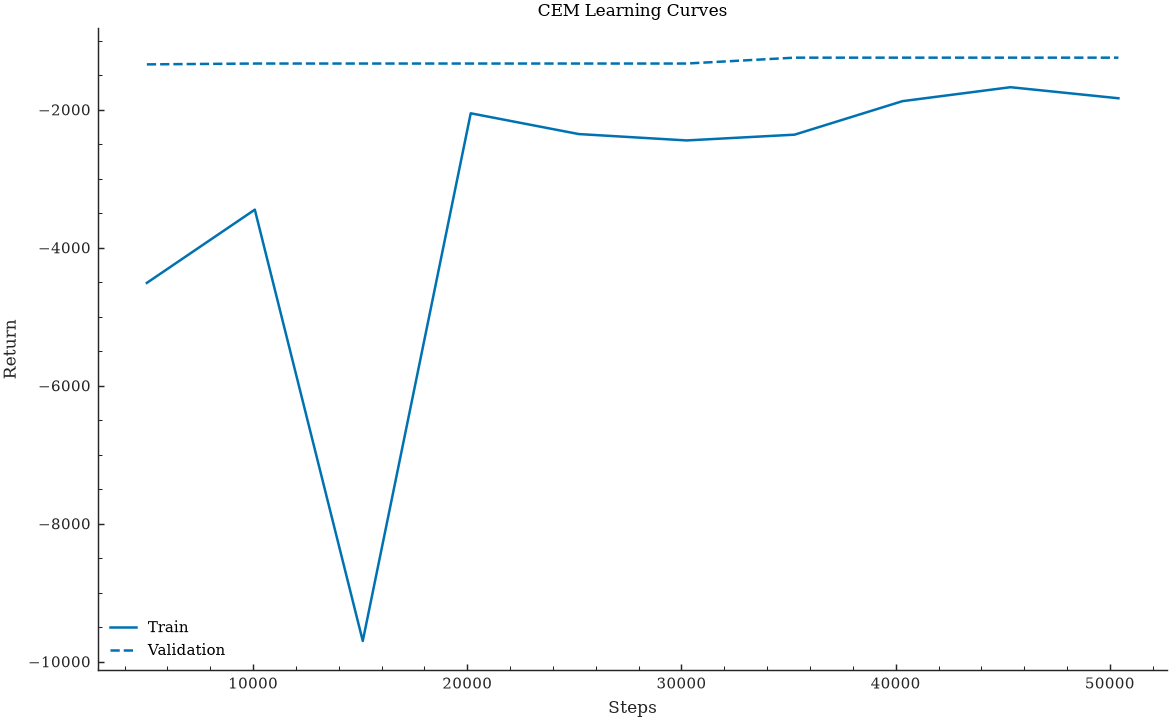

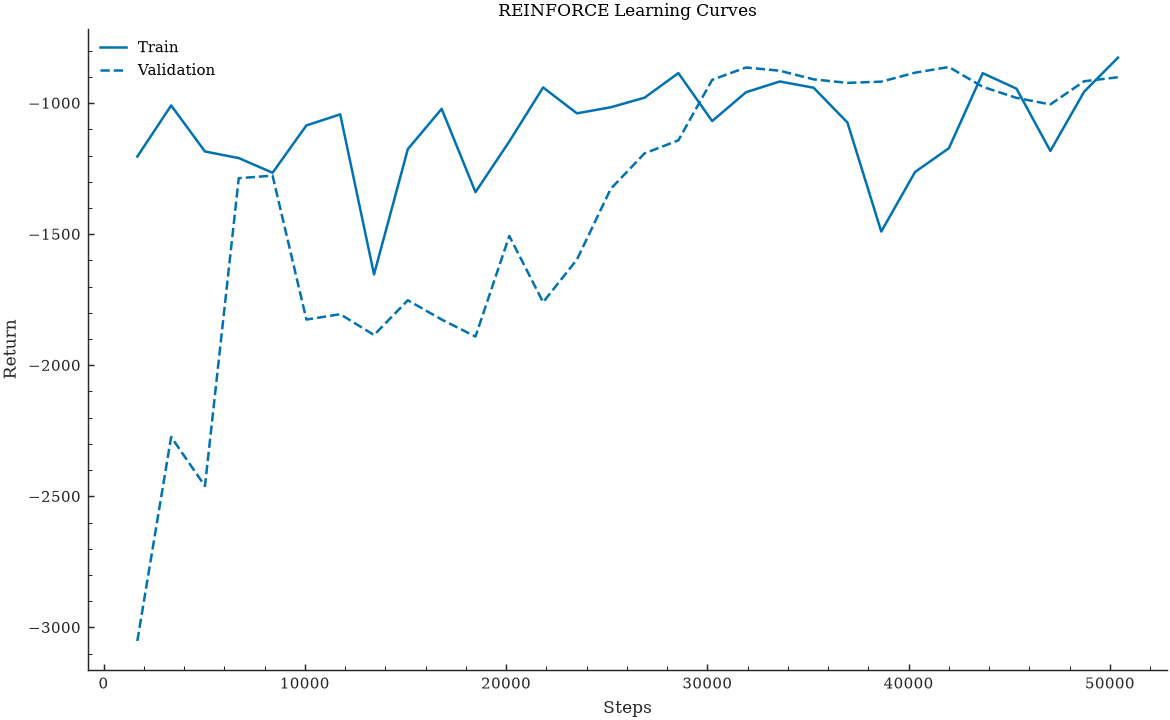

In [10]:
cem_curves = plot_learning_curves(paths_cem, title="CEM Learning Curves")
reinforce_curves = plot_learning_curves(
    paths_reinforce, title="REINFORCE Learning Curves"
)

#### **3.1.2 Policy evaluation**

In [11]:
results_cem = evaluate_marl_policy(env, best_policy_cem, num_episodes=NUM_EVAL_EPISODES)
results_reinforce = evaluate_marl_policy(
    env, best_policy_reinforce, num_episodes=NUM_EVAL_EPISODES
)

### **3.2 Your turn**

Write your **policy and your algorithm** in the cell below. Running that cell saves it as `algorithms/student_algorithm.py` (via the `%%writefile` command), which is then imported and trained in the following cells. Define your shared policy class, extend the dataclass `AlgorithmConfig` with any hyperparameters you need, and define the `train()` method with the logic of your optimization algorithm.

📏 **Rules**
* **Everything lives in one file.** The policy, its parameters, your optimisation algorithm, losses and helper code must all be defined in this cell. The submitted file must run on its own: do not import from other files you create or from the `algorithms/` directory, do not read files from `data/` and do not rely on variables defined elsewhere in the notebook.
* The signature of `train` cannot be altered: `train(env, config, seed=0)`.
    * `env`: an instance of `MARLEnv`.
    * `config`: an instance of the dataclass `AlgorithmConfig` containing the hyperparameters to be used in the training run.
    * `seed`: integer number to ensure reproducibility, optional.
* **You create the policy** inside `train`; no policy is given to you. The function must return a tuple with two elements:
    * The trained shared policy: a single object with a method `act(local_obs)` that maps **one agent's** observation, shape `(num_features,)`, to **that agent's** action, shape `(num_actions,)`, with values in $[-1, 1]$. `act` must be deterministic and must not depend on other agents' observations, on the order of the calls or on hidden state.
    * A dict containing the path(s) where your checkpoints or logs are saved (it can be empty).
* The allowed Python packages are limited to those provided in [pyproject.toml](pyproject.toml), plus `course_package`.
* Include group member information in the module docstring.

<div class="alert alert-block alert-warning">
<b>🏷️ Note:</b> the first line of the cell must be <code>%%writefile algorithms/student_algorithm.py</code>.


- Do not add code or comments above it. Every time the cell is run, the file is overwritten.

- You can add imports of the allowed packages, but keep `AlgorithmConfig` inheriting from `BaseAlgorithmConfig`.
</div>


In [ ]:
%%writefile algorithms/student_algorithm.py
"""Group XX: <member names>. Implementation of my own RL algorithm."""

from dataclasses import dataclass

import numpy as np

from course_package import MARLEnv
from course_package.utils.helpers import (
    BaseAlgorithmConfig,
    set_seed,
)


class SharedPolicy:
    """
    The single policy shared by all agents.
    """

    def __init__(self, obs_dim: int, action_dim: int):
        # YOUR POLICY PARAMETERS GO HERE (e.g. numpy arrays or a torch.nn.Module)
        self.weights = np.zeros((action_dim, obs_dim), dtype=np.float32)

    def act(self, local_obs: np.ndarray) -> np.ndarray:
        """
        Deterministic action used for evaluation and grading.

        ``local_obs`` has shape (obs_dim,). Return an array of shape
        (action_dim,) with values in [-1, 1].
        """
        return np.tanh(self.weights @ local_obs)


@dataclass
class AlgorithmConfig(BaseAlgorithmConfig):
    """Hyperparameter specification for Custom Algorithm."""

    hyperparameter_1: float = 0.5
    hyperparameter_2: int = 10
    group_identifier: str = "GROUP_NAME"


def train(
    env: MARLEnv,
    config: AlgorithmConfig,
    seed: int = 0,
) -> tuple[SharedPolicy, dict[str, str]]:
    """
    Create and train the single policy shared by all agents.
    """
    set_seed(seed)
    policy = SharedPolicy(env.observation_space.shape[1], env.action_space.shape[1])

    # YOUR CODE GOES HERE

    return policy, {}


Overwriting algorithms/student_algorithm.py


In [13]:
import importlib

from algorithms import student_algorithm

importlib.reload(student_algorithm)  # pick up the latest version of your file
from algorithms.student_algorithm import AlgorithmConfig, train


In [14]:
config = AlgorithmConfig(group_identifier="GroupXXX")
best_policy, paths = train(env, config=config, seed=0)

if paths:
    learning_curves = plot_learning_curves(paths, title="Learning Curves")

In [15]:
results = evaluate_marl_policy(env, best_policy, num_episodes=NUM_EVAL_EPISODES)

### **3.3 Submit your algorithm**
When you are happy with your algorithm, copy it to the `outputs/submissions` folder using your group identifier (this also checks that `train(env, config, seed)` and `AlgorithmConfig` are defined). That single file is everything you hand in, so make sure it does not depend on anything else.

In [16]:
export_submission(
    "algorithms/student_algorithm.py", group_id="<group_id>"
)  # TODO: change group ID

Submission saved to /home/jovyan/work/outputs/submissions/<group_id>.py


PosixPath('/home/jovyan/work/outputs/submissions/<group_id>.py')

## **4. Result comparison**

**Expert reference**

The <em>expert</em> is a model-based controller that is <b>not</b> learned: a model predictive controller (MPC) for the EV battery and a PID controller for the heat pump. It knows the system model and receives forecasts, so it is a strong reference to compare your learned policy against. It needs no training.

In [ ]:
expert = make_expert(env)
results_expert = evaluate_expert(env, expert, num_episodes=NUM_EVAL_EPISODES)

In [ ]:
global_returns_expert = np.sum(results_expert, axis=1)
global_returns_cem = np.sum(results_cem, axis=1)
global_returns_reinforce = np.sum(results_reinforce, axis=1)
global_returns = np.sum(results, axis=1)

reward_figure = plot_reward_distribution(
    [
        global_returns_expert,
        global_returns_cem,
        global_returns_reinforce,
        global_returns,
    ],
    labels=["Expert (MPC + PID)", "CEM", "REINFORCE", "Your Algorithm"],
)
for name, values in [
    ("Expert (MPC + PID)", global_returns_expert),
    ("CEM", global_returns_cem),
    ("REINFORCE", global_returns_reinforce),
    ("Your Algorithm", global_returns),
]:
    print(f"{name}: test return {values.mean():.1f} +/- {values.std():.1f}")